In [2]:
import pandas as pd
import matplotlib.pyplot as plt
 
monthly = pd.DataFrame(
    {"S1": [160, 150, 175], "S2": [120, 45, 60], "S3": [60, 80, 95]},
    index=["2026-01", "2026-02", "2026-03"],
)
print(monthly)


          S1   S2  S3
2026-01  160  120  60
2026-02  150   45  80
2026-03  175   60  95


axes in this figure: 1


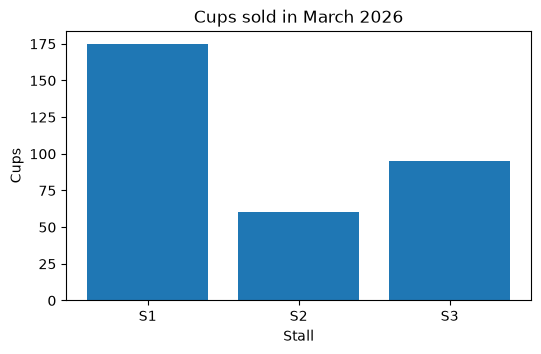

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(monthly.columns, monthly.loc["2026-03"])
ax.set_title("Cups sold in March 2026")
ax.set_xlabel("Stall")
ax.set_ylabel("Cups")
print("axes in this figure:", len(fig.axes))
plt.show()

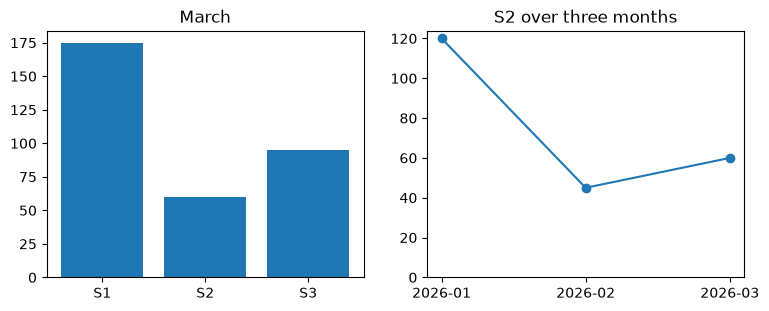

In [5]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(9, 3.2))
ax_left.bar(monthly.columns, monthly.loc["2026-03"])
ax_left.set_title("March")
ax_right.plot(monthly.index, monthly["S2"], marker="o")
ax_right.set_title("S2 over three months")
ax_right.set_ylim(bottom=0)
plt.show()

In [6]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(9, 3.2))
ax_left.bar(monthly.columns, monthly.loc["2026-03"])
ax_right.plot(monthly.index, monthly["S2"], marker="o")
plt.title("March sales")
print("left title: ", repr(ax_left.get_title()))
print("right title:", repr(ax_right.get_title()))
plt.close(fig)

left title:  ''
right title: 'March sales'


In [7]:
import os
 
def find_repo_root(marker_folder="data", start=None):
    """Search upward from the current folder for the folder that contains
    `data` -- that folder is the repo root."""
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, marker_folder)):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise FileNotFoundError(f"No '{marker_folder}' folder found")
        current = parent
 
REPO_ROOT = find_repo_root()
RAW = os.path.join(REPO_ROOT, "data", "raw")
CHART_DIR = os.path.join(REPO_ROOT, "data", "processed", "charts")
os.makedirs(CHART_DIR, exist_ok=True)
TEXT_COLUMNS = {"safety_report_id": str, "serious": str,
                "patient_age_unit": str, "country": str, "event_date": str}
EVENTS_FILE = os.path.join(RAW, "adverse_events_10k.csv")
df = pd.read_csv(EVENTS_FILE, dtype=TEXT_COLUMNS)
print(df.shape)


(6218, 8)


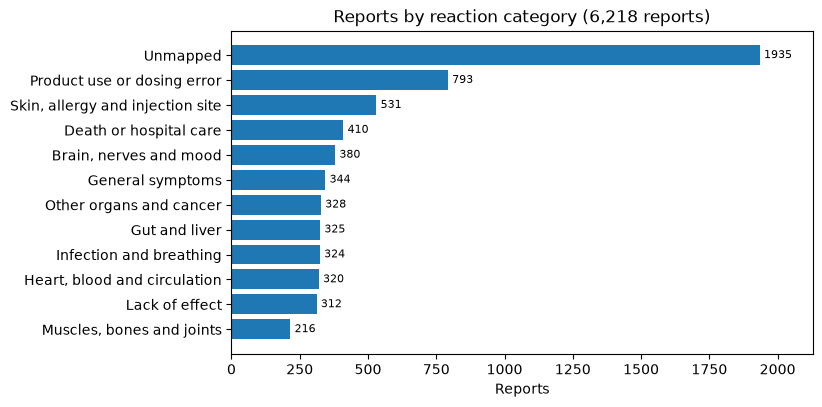

In [8]:
reaction_map = pd.read_csv(os.path.join(RAW, "reaction_categories.csv"))
rx = df.merge(reaction_map, on="reaction", how="left", validate="many_to_one")
rx["reaction_category"] = rx["reaction_category"].fillna("Unmapped")
by_category = rx["reaction_category"].value_counts().sort_values()
 
fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.barh(by_category.index, by_category.values)
ax.bar_label(bars, padding=3, fontsize=8)
ax.margins(x=0.1)
ax.set_title("Reports by reaction category (6,218 reports)")
ax.set_xlabel("Reports")
plt.show()

months: 24
lowest:  2024-12 208
highest: 2026-01 305


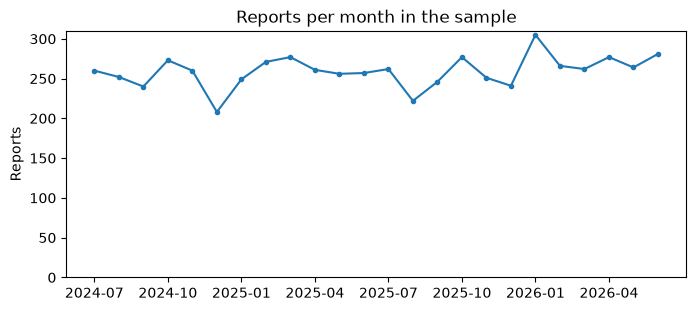

In [10]:
dates = pd.to_datetime(df["event_date"], format="%Y%m%d")
per_month = dates.dt.to_period("M").astype(str).value_counts().sort_index()
print("months:", len(per_month))
print("lowest: ", per_month.idxmin(), per_month.min())
print("highest:", per_month.idxmax(), per_month.max())
 
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(per_month.index, per_month.values, marker="o", markersize=3)
ax.set_ylim(bottom=0)
ax.set_title("Reports per month in the sample")
ax.set_ylabel("Reports")
ax.set_xticks(per_month.index[::3])
plt.show()

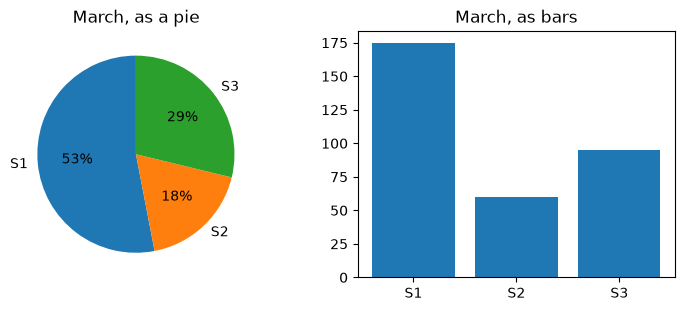

{'S1': 53.0, 'S2': 18.2, 'S3': 28.8}


In [11]:
march = monthly.loc["2026-03"]
fig, (ax_pie, ax_bar) = plt.subplots(1, 2, figsize=(9, 3.2))
ax_pie.pie(march, labels=march.index, autopct="%1.0f%%", startangle=90)
ax_pie.set_title("March, as a pie")
ax_bar.bar(march.index, march.values)
ax_bar.set_title("March, as bars")
plt.show()
print((march / march.sum() * 100).round(1).to_dict())

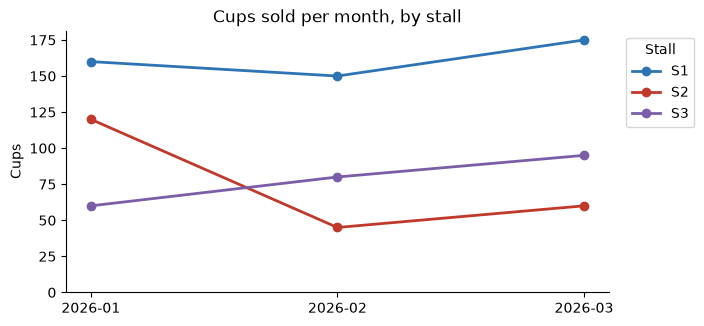

In [13]:
BLUE, HIGHLIGHT, CONTEXT = "#2E74B5", "#C0392B", "#9AA5B1"
SERIES = ["#2E74B5", "#C0392B", "#7B5EA7"]
 
fig, ax = plt.subplots(figsize=(7, 3.4))
for stall, colour in zip(monthly.columns, SERIES):
    ax.plot(monthly.index, monthly[stall], marker="o", linewidth=2,
            color=colour, label=stall)
ax.set_title("Cups sold per month, by stall")
ax.set_ylabel("Cups")
ax.set_ylim(bottom=0)
ax.legend(title="Stall", loc="upper left", bbox_to_anchor=(1.02, 1))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

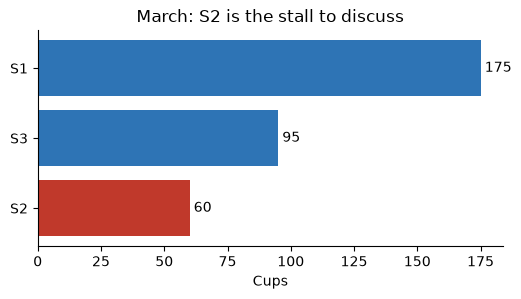

In [14]:
march = monthly.loc["2026-03"].sort_values()
colours = [HIGHLIGHT if stall == "S2" else BLUE for stall in march.index]
fig, ax = plt.subplots(figsize=(6, 2.8))
bars = ax.barh(march.index, march.values, color=colours)
ax.bar_label(bars, padding=3)
ax.set_title("March: S2 is the stall to discuss")
ax.set_xlabel("Cups")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

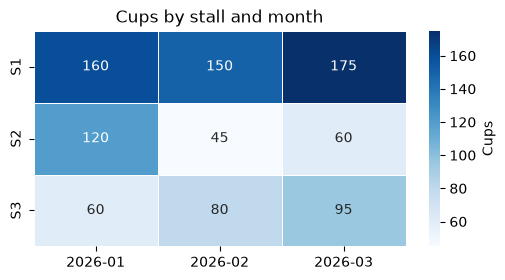

In [15]:
import seaborn as sns
 
grid = monthly.T
fig, ax = plt.subplots(figsize=(6, 2.8))
sns.heatmap(grid, annot=True, fmt="d", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "Cups"}, ax=ax)
ax.set_title("Cups by stall and month")
ax.set_xlabel("")
ax.set_ylabel("")
plt.show()


       count   25%   50%   75%
group                         
A        7.0  27.5  34.0  39.5
B        7.0  56.5  60.0  64.5


Text(0.5, 1.0, 'Toy ages by group')

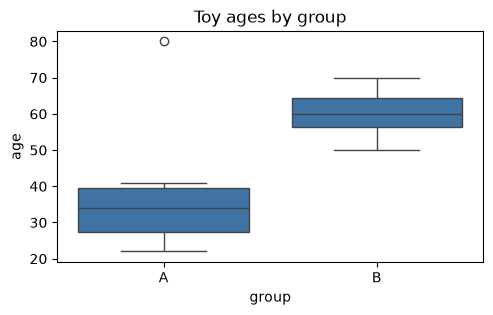

In [16]:
toy_ages = pd.DataFrame({
    "group": ["A"] * 7 + ["B"] * 7,
    "age":   [22, 25, 30, 34, 38, 41, 80, 50, 55, 58, 60, 63, 66, 70],
})
summary = toy_ages.groupby("group")["age"].describe()
print(summary[["count", "25%", "50%", "75%"]])
 
fig, ax = plt.subplots(figsize=(5.5, 3))
sns.boxplot(data=toy_ages, x="group", y="age", color=BLUE, ax=ax)
ax.set_title("Toy ages by group")

serious_label
Not serious    59.0
Serious        62.0
Name: age_years, dtype: float64


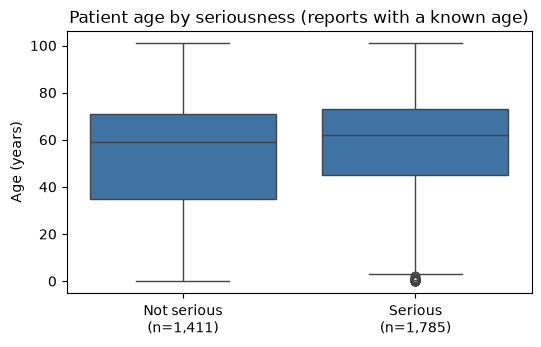

In [17]:
UNIT_TO_YEARS = {"800": 10, "801": 1, "802": 1 / 12, "803": 7 / 365.25,
                 "804": 1 / 365.25, "805": 1 / (24 * 365.25)}
age = pd.to_numeric(df["patient_age"], errors="coerce")
df["age_years"] = age * df["patient_age_unit"].map(UNIT_TO_YEARS)
df["serious_label"] = df["serious"].map({"1": "Serious", "2": "Not serious"})
 
with_age = df.dropna(subset=["age_years", "serious_label"])
n = with_age["serious_label"].value_counts()
print(with_age.groupby("serious_label")["age_years"].median())
 
order = ["Not serious", "Serious"]
fig, ax = plt.subplots(figsize=(6, 3.4))
sns.boxplot(data=with_age, x="serious_label", y="age_years", order=order,
            color=BLUE, ax=ax)
ax.set_xticks(range(len(order)), [f"{g}\n(n={n[g]:,})" for g in order])
ax.set_xlabel("")
ax.set_ylabel("Age (years)")
ax.set_title("Patient age by seriousness (reports with a known age)")
plt.show()

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(monthly.columns, monthly.loc["2026-03"], color=BLUE)
ax.set_title("Cups sold in March 2026")
 
for name, extra in [("march_100dpi.png", {"dpi": 100}),
                    ("march_200dpi.png", {"dpi": 200}),
                    ("march.svg", {})]:
    path = os.path.join(CHART_DIR, name)
    fig.savefig(path, bbox_inches="tight", **extra)
    print(f"{name:17} {os.path.getsize(path) / 1024:6.1f} KB")
plt.close(fig)
print("open figures now:", len(plt.get_fignums()))

march_100dpi.png    11.4 KB
march_200dpi.png    24.2 KB
march.svg           19.2 KB
open figures now: 0
